---
authors:
  - name: Valters Žeižis
    url: https://www.linkedin.com/in/valterszeizis/
---

# Day 8 · Utopia — *When is your utopia?*

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

Every place has a best time of year. These maps colour **Africa** and **Europe** by their **most
pleasant month** in the ERA5 climate record (1991–2020): warm but not hot, dry, sunny and calm.
Beside the maps: all 54 African capitals as a month list, and a clock of world capitals
next to Europe. Europe's utopia is a summer thing; Africa's runs right round the
calendar, because the equator splits it into opposite seasons.

*Theme: Utopia (8 Nov). Author: Valters Žeižis.*

## Method

1. From **ERA5 monthly means** (ECMWF reanalysis for Copernicus C3S), take the monthly mean of
   2 m temperature, total cloud cover, 10 m wind speed and daily precipitation:
   - **Africa** and **Europe** on ERA5's native 0.25° (~25 km) grid, for the maps
   - **the whole globe** on a 1° grid (interpolated by the CDS), for the world capitals
2. Average 1991–2020 into 12 monthly maps.
3. Score each month, out of 100:
   - **warm, not hot** (40): best at a daily-mean temperature of 19 °C (about 23–25 °C in the
     afternoon). Daily means work everywhere; a fixed hour like 12 UTC would be afternoon in
     Europe but night in the Pacific.
   - **dry** (25): loses points with every mm/day of rain
   - **sunny** (25): the fraction of sky without cloud
   - **calm** (10): loses points once wind is above 4 m/s
4. **Clean areas, not speckle (maps):** smooth the monthly scores over ~60 km, take the best
   month, then a 3×3 majority vote removes single stray grid boxes.
5. **Two utopias a year:** where the runner-up month is within 3 points of the winner **and at
   least two months away** (two separate good seasons, not July vs August), the map is hatched
   and the clock gives the second month in brackets.
6. **Bonus:** Europe 1961–1990 vs 1991–2020, to see whether utopia has moved in the calendar.

In the tropics it's warm all year, so the dry, sunny season decides. The score is simple on
purpose: change the ideal temperature and you get a different utopia.

## Licence & attribution

**ERA5**: Copernicus Climate Change Service (C3S), via the Climate Data Store.
*Contains modified Copernicus Climate Change Service information (2026).* Neither the European
Commission nor ECMWF is responsible for any use of this information.
Hersbach et al. (2023): ERA5 monthly averaged data on single levels from 1940 to present,
C3S CDS, DOI: [10.24381/cds.f17050d7](https://doi.org/10.24381/cds.f17050d7).
Coastlines and borders: **Natural Earth** (public domain).

## Tools

`cdsapi` (retrieve; needs a free CDS account, your key in `~/.cdsapirc`, and the ERA5
monthly licence accepted on the dataset page) · `xarray` (read) · `scipy` (smooth) ·
`cartopy` + `matplotlib` (render)

```bash
pip install cdsapi xarray netcdf4 scipy cartopy matplotlib
```

In [ ]:
from pathlib import Path
import zipfile

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cdsapi
from scipy import ndimage

# --- house style (as in the other days of the repo) ---
import logging, warnings
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)      # font fallback (to Arial) is expected
warnings.filterwarnings("ignore", message="invalid value encountered in create_collection")   # Natural Earth shapes
warnings.filterwarnings("ignore", message="In a future version of xarray")                     # merge default notice
import os
import matplotlib.image as mpimg
from matplotlib import patheffects as pe
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
DB = ["Avenir Next Demi Bold", "Arial", "DejaVu Sans"]          # titles
AUTHOR = "Valters Žeižis"

def add_logo(fig, white=True, rect=(0.855, 0.016, 0.125, 0.05)):
    p = f"assets/ECMWF_Core_Logo_{'WHITE' if white else 'RGB'}.png"
    if os.path.exists(p):
        a = fig.add_axes(rect); a.imshow(mpimg.imread(p)); a.set_anchor("E"); a.axis("off")

def add_tag(fig, day, theme, color, x=0.98):
    fig.text(x, 0.958, "#30DayMapChallenge 2026", fontsize=10, color=color, ha="right")
    fig.text(x, 0.936, f"Day {day} · {theme}", fontsize=10, color=color, ha="right")

def land_mask(da):
    # True over land (Natural Earth), on the grid of `da`
    import shapely
    import cartopy.io.shapereader as shpreader
    from shapely.ops import unary_union
    land = unary_union(list(shpreader.Reader(shpreader.natural_earth("50m", "physical", "land")).geometries()))
    lon2d, lat2d = np.meshgrid(da.longitude.values, da.latitude.values)
    return shapely.contains_xy(land, lon2d, lat2d)

def month_edges_and_labels(ax, best, line_color, text_color, halo_color, mask=None, min_cells=250,
                           fontsize=10, line_alpha=0.5, line_width=0.4, max_per_month=2):
    # colour-blind friendly but quiet: each boundary between two month areas drawn once, thin and
    # semi-transparent, and the month name only on the biggest area(s) of each month
    lat, lon = best.latitude.values, best.longitude.values
    vals = np.nan_to_num(best.values.astype(float), nan=0).astype(int)
    if mask is not None:
        vals = np.where(mask, vals, 0)
    # the outline of each month area, once per month: every border is then traced exactly twice
    # (once from each side), so all borders look the same weight. Before, a Jan/Dec border was
    # drawn ~10 times over (one line per level in between) and looked much heavier.
    a = 1 - (1 - line_alpha) ** 0.5                      # two overlapping strokes -> line_alpha
    for k in np.unique(vals[vals > 0]):
        ax.contour(lon, lat, (vals == k).astype(float), levels=[0.5],
                   colors=[mcolors.to_rgba(line_color, a)], linewidths=line_width,
                   transform=pc, zorder=2.5)
    halo = [pe.withStroke(linewidth=1.6, foreground=mcolors.to_rgba(halo_color, 0.7))]
    for k in range(1, 13):
        lab, n = ndimage.label(vals == k)
        if n == 0:
            continue
        sizes = ndimage.sum(np.ones_like(lab), lab, range(1, n + 1))
        for j in np.argsort(sizes)[::-1][:max_per_month]:
            if sizes[j] < min_cells:
                break
            comp = lab == j + 1
            d = ndimage.distance_transform_edt(comp)              # most "inside" point of the area
            iy, ix = np.unravel_index(d.argmax(), d.shape)
            ax.text(lon[ix], lat[iy], MONTHS[k - 1], transform=pc, ha="center", va="center",
                    fontsize=fontsize, fontfamily=DB, color=text_color, alpha=0.9, zorder=6,
                    path_effects=halo)

PERIOD = (1991, 2020)               # the climatology shown
PERIOD_OLD = (1961, 1990)           # Europe only, for the bonus comparison; None to skip
AREAS = {"europe": [75, -30, 33, 65],     # N, W, S, E: wide enough for no empty corners
         "africa": [38, -26, -36, 60]}    # includes Cabo Verde, Mauritius, Seychelles
T_IDEAL, T_WIDTH = 19.0, 6.0        # °C, daily mean
SMOOTH_KM = 60                      # maps only: smooth scores before picking (0 = raw grid)
CLOSE_PTS = 3                       # runner-up within this many points ...
MIN_APART = 2                       # ... and at least this many months away -> "two utopias"

DATA = Path("data"); DATA.mkdir(exist_ok=True)   # repo .gitignore skips data/*.nc
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

ECMWF_SITES = {"Reading (UK)": (51.44, -0.94), "Bonn (DE)": (50.73, 7.10),
               "Bologna (IT)": (44.52, 11.34)}

AFRICA = {  # the 54 capitals
    "Algiers": (36.75, 3.06), "Luanda": (-8.84, 13.23), "Porto-Novo": (6.50, 2.60),
    "Gaborone": (-24.65, 25.91), "Ouagadougou": (12.37, -1.52), "Gitega": (-3.43, 29.93),
    "Praia": (14.93, -23.51), "Yaoundé": (3.85, 11.50), "Bangui": (4.39, 18.56),
    "N'Djamena": (12.13, 15.06), "Moroni": (-11.70, 43.26), "Kinshasa": (-4.44, 15.27),
    "Brazzaville": (-4.26, 15.24), "Yamoussoukro": (6.83, -5.29), "Djibouti": (11.59, 43.15),
    "Cairo": (30.04, 31.24), "Malabo": (3.75, 8.78), "Asmara": (15.32, 38.93),
    "Mbabane": (-26.31, 31.14), "Addis Ababa": (9.03, 38.74), "Libreville": (0.42, 9.47),
    "Banjul": (13.45, -16.58), "Accra": (5.60, -0.19), "Conakry": (9.64, -13.58),
    "Bissau": (11.86, -15.60), "Nairobi": (-1.29, 36.82), "Maseru": (-29.31, 27.48),
    "Monrovia": (6.30, -10.80), "Tripoli": (32.89, 13.19), "Antananarivo": (-18.88, 47.51),
    "Lilongwe": (-13.96, 33.79), "Bamako": (12.64, -8.00), "Nouakchott": (18.08, -15.98),
    "Port Louis": (-20.16, 57.50), "Rabat": (34.02, -6.84), "Maputo": (-25.97, 32.57),
    "Windhoek": (-22.56, 17.08), "Niamey": (13.51, 2.11), "Abuja": (9.08, 7.40),
    "Kigali": (-1.94, 30.06), "São Tomé": (0.34, 6.73), "Dakar": (14.72, -17.47),
    "Victoria": (-4.62, 55.45), "Freetown": (8.48, -13.23), "Mogadishu": (2.05, 45.32),
    "Pretoria": (-25.75, 28.19), "Juba": (4.85, 31.58), "Khartoum": (15.50, 32.56),
    "Dodoma": (-6.16, 35.75), "Lomé": (6.13, 1.22), "Tunis": (36.81, 10.18),
    "Kampala": (0.35, 32.58), "Lusaka": (-15.39, 28.32), "Harare": (-17.83, 31.05)}
assert len(AFRICA) == 54

WORLD = {   # capitals spread over climates and both hemispheres (for the Europe poster)
    "Reykjavík": (64.15, -21.94), "Oslo": (59.91, 10.75), "Riga": (56.95, 24.11),
    "London": (51.51, -0.13), "Berlin": (52.52, 13.40), "Paris": (48.86, 2.35),
    "Madrid": (40.42, -3.70), "Rome": (41.90, 12.50), "Athens": (37.98, 23.73),
    "Ankara": (39.93, 32.85), "Moscow": (55.76, 37.62), "Ottawa": (45.42, -75.70),
    "Washington": (38.91, -77.04), "Mexico City": (19.43, -99.13), "Havana": (23.11, -82.37),
    "Bogotá": (4.71, -74.07), "Lima": (-12.05, -77.04), "Brasília": (-15.79, -47.88),
    "Buenos Aires": (-34.60, -58.38), "Santiago": (-33.45, -70.67), "Rabat": (34.02, -6.84),
    "Cairo": (30.04, 31.24), "Dakar": (14.72, -17.47), "Abuja": (9.08, 7.40),
    "Addis Ababa": (9.03, 38.74), "Nairobi": (-1.29, 36.82), "Kinshasa": (-4.44, 15.27),
    "Pretoria": (-25.75, 28.19), "Antananarivo": (-18.88, 47.51), "Riyadh": (24.71, 46.68),
    "Tehran": (35.69, 51.39), "Astana": (51.17, 71.45), "New Delhi": (28.61, 77.21),
    "Kathmandu": (27.72, 85.32), "Dhaka": (23.81, 90.41), "Ulaanbaatar": (47.89, 106.91),
    "Beijing": (39.90, 116.41), "Seoul": (37.57, 126.98), "Tokyo": (35.68, 139.69),
    "Bangkok": (13.76, 100.50), "Hanoi": (21.03, 105.85), "Manila": (14.60, 120.98),
    "Jakarta": (-6.21, 106.85), "Canberra": (-35.28, 149.13), "Wellington": (-41.29, 174.78),
    "Suva": (-18.14, 178.44)}

## Retrieve

Three requests, all *monthly averaged reanalysis*:

- **Europe**, 0.25°, 1961–2020 (the old period is only for the bonus)
- **Africa**, 0.25°, 1991–2020
- **World**, interpolated by the CDS to 1°, 1991–2020

Each is cached in `data/` under a name that includes its area or grid, so re-runs only fetch
what's missing (here: Africa, if Europe and World are already there). The CDS queue can take a
few minutes.

In [2]:
VARS = ["2m_temperature", "total_cloud_cover", "10m_wind_speed", "total_precipitation"]
months = [f"{m:02d}" for m in range(1, 13)]
years = lambda a, b: [str(y) for y in range(a, b + 1)]

REQUESTS = {
    "europe": dict(year=years((PERIOD_OLD or PERIOD)[0], PERIOD[1]), area=AREAS["europe"]),
    "africa": dict(year=years(*PERIOD), area=AREAS["africa"]),
    "world":  dict(year=years(*PERIOD), grid=[1.0, 1.0]),
}

client = cdsapi.Client()
FILES = {}
for key, extra in REQUESTS.items():
    tag = "_".join(str(x) for x in extra.get("area", extra.get("grid")))
    target = DATA / f"day08_era5_monthly_{key}_{extra['year'][0]}-{extra['year'][-1]}_{tag}.nc"
    if not target.exists():
        req = dict(product_type=["monthly_averaged_reanalysis"], variable=VARS, month=months,
                   time=["00:00"], data_format="netcdf", download_format="unarchived", **extra)
        client.retrieve("reanalysis-era5-single-levels-monthly-means", req).download(str(target))
    FILES[key] = target
    print(key, target.name, f"{target.stat().st_size / 1e6:.0f} MB")

europe day08_era5_monthly_europe_1961-2020_75_-30_33_65.nc 298 MB
africa day08_era5_monthly_africa_1991-2020_38_-26_-36_60.nc 238 MB
world day08_era5_monthly_world_1991-2020_1.0_1.0.nc 178 MB


## Read & process

In [3]:
def open_cds(path):
    # the CDS sometimes zips netCDF even when asked not to: handle both
    if zipfile.is_zipfile(path):
        parts = []
        with zipfile.ZipFile(path) as z:
            for name in z.namelist():
                out = path.parent / f"{path.stem}_{Path(name).name}"   # stays in data/*.nc (git-ignored)
                out.write_bytes(z.read(name))
                parts.append(out)
        ds = xr.merge([xr.open_dataset(f) for f in parts], compat="override")
    else:
        ds = xr.open_dataset(path)
    t = next(d for d in ("valid_time", "time", "date") if d in ds.dims)
    ds = ds.rename({t: "month_start"}).squeeze(drop=True)
    ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude")
    return ds.sortby("latitude")

def pick(ds, *names):
    for n in names:
        if n in ds.data_vars:
            return ds[n]
    raise KeyError(f"none of {names} in {list(ds.data_vars)}")

def fields(ds):
    return xr.Dataset({"t": pick(ds, "t2m", "2t") - 273.15,          # °C, daily mean
                       "cloud": pick(ds, "tcc"),                       # 0..1
                       "wind": pick(ds, "si10", "10si", "ws10"),       # m/s
                       "rain": pick(ds, "tp") * 1000})                 # m/day -> mm/day

def climatology(f, period):
    sel = f.sel(month_start=f.month_start.dt.year.isin(range(period[0], period[1] + 1)))
    return sel.groupby("month_start.month").mean().load()

def score(c):
    return (40 * np.exp(-((c.t - T_IDEAL) / T_WIDTH) ** 2)
            + 25 * np.exp(-c.rain / 2.5)
            + 25 * (1 - c.cloud)
            + 10 * np.exp(-(np.maximum(c.wind - 4, 0) / 4) ** 2))

def months_apart(a, b):
    d = np.abs(a - b) % 12
    return np.minimum(d, 12 - d)

def pick_best(sc, smooth_km=0):
    # best month, runner-up and whether it's "two utopias" (close AND >= MIN_APART months away)
    v = sc.transpose("month", "latitude", "longitude").values
    if smooth_km:
        sig = smooth_km / (abs(float(sc.latitude[1] - sc.latitude[0])) * 111)   # km -> grid boxes
        v = ndimage.gaussian_filter(v, sigma=(0, sig, sig), mode="nearest")
    order = np.argsort(v, axis=0)
    first, second = order[-1], order[-2]
    gap = np.take_along_axis(v, first[None], 0)[0] - np.take_along_axis(v, second[None], 0)[0]
    best, runner = first + 1, second + 1
    if smooth_km:                         # 3x3 majority vote: no single stray grid boxes
        best = ndimage.generic_filter(best, lambda w: np.bincount(w.astype(int)).argmax(), size=3, mode="nearest")
    two = (gap < CLOSE_PTS) & (months_apart(best, runner) >= MIN_APART)
    as_da = lambda a: xr.DataArray(a, coords={"latitude": sc.latitude, "longitude": sc.longitude},
                                   dims=("latitude", "longitude"))
    return as_da(best), as_da(runner), as_da(two)

def at_points(best, runner, two, places):
    # {name: (best month, second month or None, latitude)}
    out = {}
    for name, (la, lo) in places.items():
        at = dict(latitude=la, longitude=lo, method="nearest")
        m, r, t = int(best.sel(**at)), int(runner.sel(**at)), bool(two.sel(**at))
        out[name] = (m, r if t else None, la)
    return out

def show(points, label):
    print(label)
    for m in range(1, 13):
        names = [c + (f" ({MONTHS[r - 1]})" if r else "") for c, (mm, r, _) in points.items() if mm == m]
        print(f"  {MONTHS[m - 1]}: {', '.join(names) or '—'}")

maps = {}
for key in ("europe", "africa"):
    f = fields(open_cds(FILES[key]))
    best, runner, two = pick_best(score(climatology(f, PERIOD)), SMOOTH_KM)
    maps[key] = dict(fields=f, best=best, runner=runner, two=two)
    print(f"{key}: two-utopia areas cover {float(two.mean()) * 100:.0f} % of the map")

# capitals: Africa straight from the 0.25° Africa data (unsmoothed, single points)
ab, ar, at = pick_best(score(climatology(maps["africa"]["fields"], PERIOD)))
africa_caps = at_points(ab, ar, at, AFRICA)
show(africa_caps, "African capitals")

# world capitals from the 1° global grid, ECMWF sites from the Europe map
wb, wr, wt = pick_best(score(climatology(fields(open_cds(FILES["world"])), PERIOD)))
world_caps = at_points(wb, wr, wt, WORLD)
show(world_caps, "World capitals")
sites = at_points(maps["europe"]["best"], maps["europe"]["runner"], maps["europe"]["two"], ECMWF_SITES)
print("ECMWF sites:", {k: MONTHS[m - 1] for k, (m, _, _) in sites.items()})

europe: two-utopia areas cover 9 % of the map
africa: two-utopia areas cover 20 % of the map
African capitals
  Jan: Porto-Novo, Ouagadougou, N'Djamena, Malabo, Banjul (Apr), Conakry, Bissau, Monrovia, Bamako, Nouakchott, Niamey, Juba, Khartoum, Lomé
  Feb: Addis Ababa, Freetown, Mogadishu
  Mar: Praia, Dakar
  Apr: —
  May: Algiers, Tripoli, Tunis
  Jun: Rabat
  Jul: Luanda, Gitega, Kinshasa, Brazzaville, Libreville, Maputo, Kigali, São Tomé, Victoria (Oct), Dodoma, Kampala
  Aug: Gaborone, Moroni, Accra (Jan), Lilongwe (May), Port Louis, Lusaka
  Sep: Mbabane (May), Nairobi (Jan), Windhoek, Pretoria, Harare
  Oct: Asmara, Antananarivo
  Nov: Cairo (Mar), Maseru (Mar)
  Dec: Yaoundé, Bangui, Yamoussoukro, Djibouti, Abuja
World capitals
  Jan: Havana, Bogotá, Manila
  Feb: Addis Ababa, Nairobi, Wellington
  Mar: Mexico City, Canberra (Dec)
  Apr: Dakar
  May: Washington, Lima, Beijing, Tokyo (Oct)
  Jun: Rome, Rabat
  Jul: Reykjavík, Oslo, Riga, London, Paris, Moscow, Brasília, Kinshas

## Plot

One poster function, used twice. Left: the map, coloured by the best month and hatched where
there are two utopias a year. Right: the capitals at their best month (a month list for Africa, a clock for
Europe); the colours are the legend.

In [4]:
BG, INK, MUTED = "#f5f1ea", "#2a2622", "#7d756b"
# a seasonal colour wheel: winter blues -> spring greens -> summer golds -> autumn reds -> back
WHEEL = ["#2f4b8f", "#3f74b5", "#3e9aa6", "#5fae6e", "#a5c04f", "#e8c547",
         "#f2a03d", "#e5713a", "#c94f4f", "#9c4673", "#6e4a8e", "#3c4a92"]
CMAP = mcolors.ListedColormap(WHEEL)
plt.rcParams["hatch.color"] = (0.16, 0.15, 0.13, 0.5)
plt.rcParams["hatch.linewidth"] = 0.6
pc = ccrs.PlateCarree()

def draw_map(fig, rect, m, proj, extent):
    ax = fig.add_axes(rect, projection=proj, facecolor=BG)
    ax.set_extent(extent, crs=pc)
    best, two = m["best"], m["two"]
    lat, lon = best.latitude.values, best.longitude.values
    ax.pcolormesh(lon, lat, best, cmap=CMAP, vmin=0.5, vmax=12.5, transform=pc, shading="nearest", zorder=1)
    if bool(two.any()):
        ax.contourf(lon, lat, two.astype(float), levels=[0.5, 1.5], colors="none", hatches=["////"],
                    transform=pc, zorder=2)
    ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor=BG, zorder=3)
    ax.add_feature(cfeature.LAKES.with_scale("50m"), facecolor=BG, zorder=3)
    ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor=INK, lw=0.6, zorder=4)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor=INK, lw=0.35, alpha=0.45, zorder=4)
    ax.spines["geo"].set_visible(False)
    return ax

def draw_clock(fig, rect, points):
    cx = fig.add_axes(rect, projection="polar")
    cx.set_theta_zero_location("N"); cx.set_theta_direction(-1)
    centre = np.deg2rad(np.arange(12) * 30)
    cx.bar(centre, 0.32, width=np.deg2rad(30), bottom=0.58, color=WHEEL, edgecolor=BG, lw=2)
    for th, mname in zip(centre, MONTHS):
        d = np.rad2deg(th)
        cx.text(th, 0.74, mname, ha="center", va="center", fontsize=10, color="white", fontfamily=DB,
                rotation=-d + (180 if 90 < d < 270 else 0), rotation_mode="anchor")   # never upside down
    # target angle: the month's wedge, north-to-south within it; then push apart so no label
    # overlaps (crowded months spill into the neighbours, with a tick back to their real month)
    items = []
    for m in range(1, 13):
        here = sorted([(c, r, la) for c, (mm, r, la) in points.items() if mm == m], key=lambda x: -x[2])
        offs = np.linspace(-11, 11, len(here)) if len(here) > 1 else [0]
        items += [((m - 1) * 30 + off, city, r) for (city, r, _), off in zip(here, offs)]
    items.sort(key=lambda x: x[0])
    target = np.array([t for t, _, _ in items], float)
    gap = min(5.5, 0.95 * 360 / max(len(items), 1))
    # exact 1-D label spreading: merge neighbours into clusters, centre each cluster on its targets
    clusters = [[i] for i in range(len(target))]
    def place(c):
        mid = target[c].mean()
        return mid + (np.arange(len(c)) - (len(c) - 1) / 2) * gap
    merged = True
    while merged:
        merged = False
        for k in range(len(clusters) - 1):
            if place(clusters[k])[-1] + gap > place(clusters[k + 1])[0]:
                clusters[k] += clusters.pop(k + 1)
                merged = True
                break
    ang = np.concatenate([place(c) for c in clusters])
    for (t, city, r), deg in zip(items, ang):
        cx.plot([np.deg2rad(t), np.deg2rad(deg)], [0.905, 0.95], color=MUTED, lw=0.5, clip_on=False)
        right = (deg % 360) < 180
        label = city + (f" ({MONTHS[r - 1]})" if r else "")
        cx.text(np.deg2rad(deg), 0.97, label, rotation=90 - deg if right else 270 - deg,
                rotation_mode="anchor", ha="left" if right else "right", va="center",
                fontsize=8, color=INK, clip_on=False)
    cx.set_ylim(0, 1.45); cx.axis("off")              # room for the labels outside the ring
    return cx

def credits(fig, extra=""):
    fig.text(0.02, 0.035,
             f"Score: daily-mean temperature near {T_IDEAL:.0f} °C (40) + dry (25) + sunny (25) + calm wind (10) · "
             f"ERA5 monthly means, 0.25° (~25 km), maps smoothed over ~{SMOOTH_KM} km{extra}",
             fontsize=9.5, color=INK)
    fig.text(0.02, 0.015,
             "Contains modified Copernicus Climate Change Service information (2026) · ERA5, ECMWF / C3S · "
             "Natural Earth · Map: Valters Žeižis · #30DayMapChallenge 2026 · Day 8 · Utopia", fontsize=8.5, color=MUTED)

SUB = (f"{PERIOD[0]}–{PERIOD[1]}:\n"
       "Hatched areas = two utopias a year; (alt) = the secondary season.")

### Africa

A dark poster so the continent carries the colour. Everything that isn't Africa is masked using
Natural Earth country shapes (UN region "Africa", so Madagascar and the island states stay in).
Lakes keep their colour and get an outline. The capitals are a month list: the bar is how many
capitals peak in that month, followed by their names (north to south).

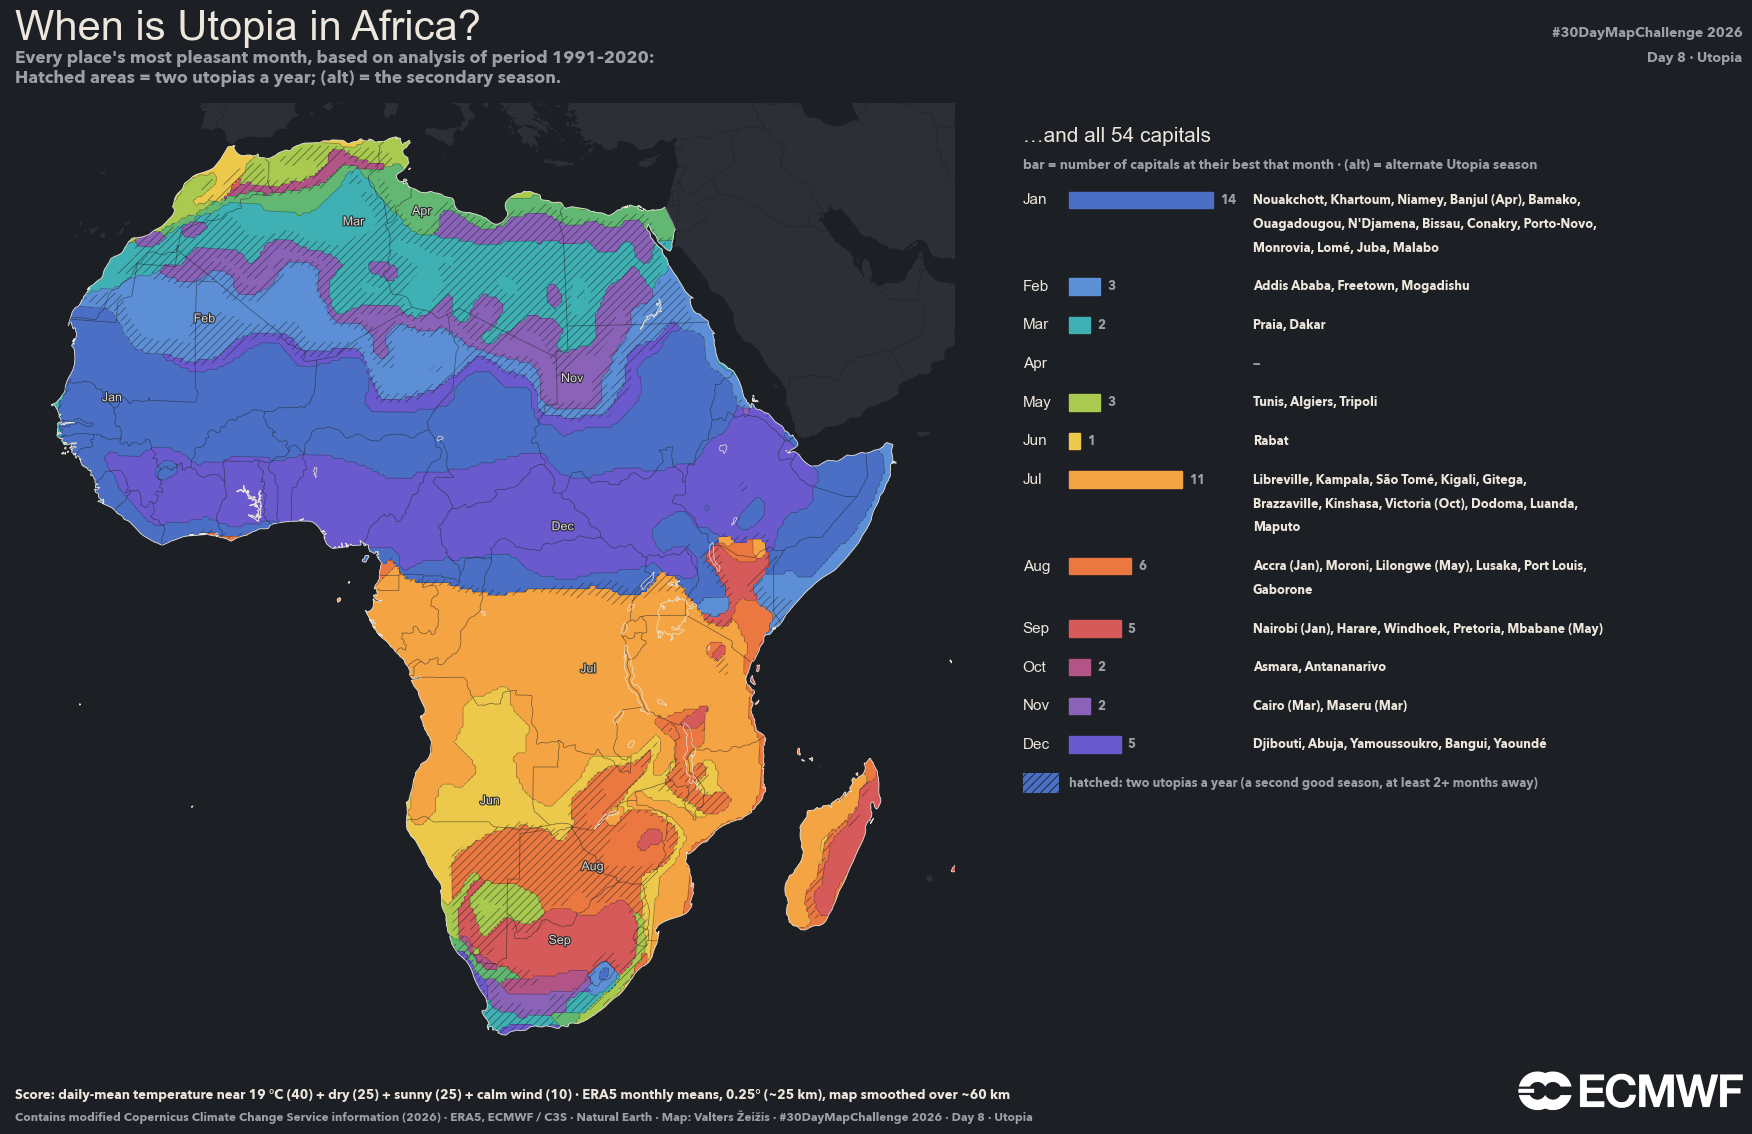

In [8]:
import textwrap
import shapely
from shapely.geometry import box
from shapely.ops import unary_union
import cartopy.io.shapereader as shpreader

D_BG, D_INK, D_MUTED, D_LAND = "#1c1f23", "#ece6dc", "#9aa0a6", "#2c3036"
# same seasonal wheel, with the winter blues lifted so they read on a dark background
D_WHEEL = ["#4a6fc4", "#5d8fd6", "#3fb0b3", "#62b872", "#a9c94f", "#ecc94a",
           "#f4a443", "#ea7840", "#d65a5a", "#b25486", "#8a63b8", "#6a5acd"]
D_CMAP = mcolors.ListedColormap(D_WHEEL)

countries = list(shpreader.Reader(shpreader.natural_earth("50m", "cultural", "admin_0_countries")).records())
is_africa = lambda r: r.attributes.get("REGION_UN") == "Africa"
africa = unary_union([r.geometry for r in countries if is_africa(r)])
others = unary_union([r.geometry for r in countries if not is_africa(r)])
frame = box(-45, -50, 75, 50)

m = maps["africa"]
lat, lon = m["best"].latitude.values, m["best"].longitude.values
lon2d, lat2d = np.meshgrid(lon, lat)
inside = shapely.contains_xy(africa.buffer(0.35), lon2d, lat2d)   # grid boxes touching Africa
best_af = m["best"].where(inside)
two_af = (m["two"] & inside).astype(float)

fig = plt.figure(figsize=(18, 11.5), facecolor=D_BG)
ax = fig.add_axes([0.0, 0.06, 0.56, 0.84],
                  projection=ccrs.LambertAzimuthalEqualArea(central_longitude=18, central_latitude=2),
                  facecolor=D_BG)
ax.set_extent([-20, 56, -36, 38], crs=pc)
ax.pcolormesh(lon, lat, best_af, cmap=D_CMAP, vmin=0.5, vmax=12.5, transform=pc, shading="nearest", zorder=1)
plt.rcParams["hatch.color"] = (0.11, 0.12, 0.14, 0.55)
ax.contourf(lon, lat, two_af, levels=[0.5, 1.5], colors="none", hatches=["////"], transform=pc, zorder=2)
month_edges_and_labels(ax, best_af, D_BG, D_INK, D_BG, min_cells=700, max_per_month=1,
                       fontsize=9, line_alpha=0.45, line_width=0.45)   # knobs: tune here
ax.add_geometries([frame.difference(africa)], crs=pc, facecolor=D_BG, edgecolor="none", zorder=3)  # sea
ax.add_geometries([others], crs=pc, facecolor=D_LAND, edgecolor="none", zorder=4)              # not Africa
ax.add_geometries([africa], crs=pc, facecolor="none", edgecolor=D_INK, lw=0.6, zorder=5)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor=D_BG, lw=0.5, alpha=0.6, zorder=5)
lakes = [g for g in shpreader.Reader(shpreader.natural_earth("50m", "physical", "lakes")).geometries()
         if g.intersects(africa)]                       # only Africa's lakes get an outline
ax.add_geometries(lakes, crs=pc, facecolor="none", edgecolor=D_INK, lw=0.5, zorder=5)
ax.spines["geo"].set_visible(False)

# --- capitals by month: bar = how many, then the names
lx = fig.add_axes([0.58, 0.08, 0.40, 0.80]); lx.axis("off"); lx.set_xlim(0, 1); lx.set_ylim(0, 1)
by_month = {k: sorted([(c, r, la) for c, (mm, r, la) in africa_caps.items() if mm == k], key=lambda x: -x[2])
            for k in range(1, 13)}
nmax = max(len(v) for v in by_month.values())
LINE, PAD = 0.026, 0.016
lx.text(0.0, 1.0, "…and all 54 capitals", fontsize=15, fontfamily=DB, color=D_INK, va="top")
lx.text(0.0, 0.965, "bar = number of capitals at their best that month · (alt) = alternate Utopia season",
        fontsize=9.5, color=D_MUTED, va="top")
y = 0.92
for k in range(1, 13):
    names = [c + (f" ({MONTHS[r - 1]})" if r else "") for c, r, _ in by_month[k]]
    lines = textwrap.wrap(", ".join(names), 58, break_on_hyphens=False) or ["—"]
    n = len(by_month[k])
    lx.text(0.0, y, MONTHS[k - 1], fontsize=11, fontfamily=DB, color=D_INK, va="center")
    if n:
        lx.add_patch(plt.Rectangle((0.065, y - 0.009), 0.2 * n / nmax, 0.018, color=D_WHEEL[k - 1]))
    lx.text(0.075 + 0.2 * n / nmax, y, str(n) if n else "", fontsize=9, color=D_MUTED, va="center")
    for i, line in enumerate(lines):
        lx.text(0.32, y - i * LINE, line, fontsize=9, va="center", color=D_INK if n else D_MUTED)
    y -= LINE * len(lines) + PAD
lx.add_patch(plt.Rectangle((0.0, y - 0.011), 0.05, 0.022, facecolor=D_WHEEL[0], edgecolor="none"))
lx.add_patch(plt.Rectangle((0.0, y - 0.011), 0.05, 0.022, facecolor="none", edgecolor=D_BG,
                           hatch="////", lw=0))
lx.text(0.065, y, "hatched: two utopias a year (a second good season, at least 2+ months away)",
        fontsize=9, color=D_MUTED, va="center")


fig.text(0.02, 0.955, "When is Utopia in Africa?", fontsize=30, fontfamily=DB, color=D_INK)
fig.text(0.02, 0.918, "Every place's most pleasant month, based on analysis of period " + SUB, fontsize=12.5, color=D_MUTED)
fig.text(0.02, 0.035,
         f"Score: daily-mean temperature near {T_IDEAL:.0f} °C (40) + dry (25) + sunny (25) + calm wind (10) · "
         f"ERA5 monthly means, 0.25° (~25 km), map smoothed over ~{SMOOTH_KM} km",
         fontsize=9.5, color=D_INK)
fig.text(0.02, 0.015,
         "Contains modified Copernicus Climate Change Service information (2026) · ERA5, ECMWF / C3S · "
         "Natural Earth · Map: Valters Žeižis · #30DayMapChallenge 2026 · Day 8 · Utopia", fontsize=8.5, color=D_MUTED)
add_logo(fig, white=True); add_tag(fig, 8, "Utopia", D_MUTED)
fig.savefig("day08_utopia_africa.png", dpi=200, facecolor=D_BG)
plt.show()
plt.rcParams["hatch.color"] = (0.16, 0.15, 0.13, 0.5)   # back to the light posters' hatching

### Europe

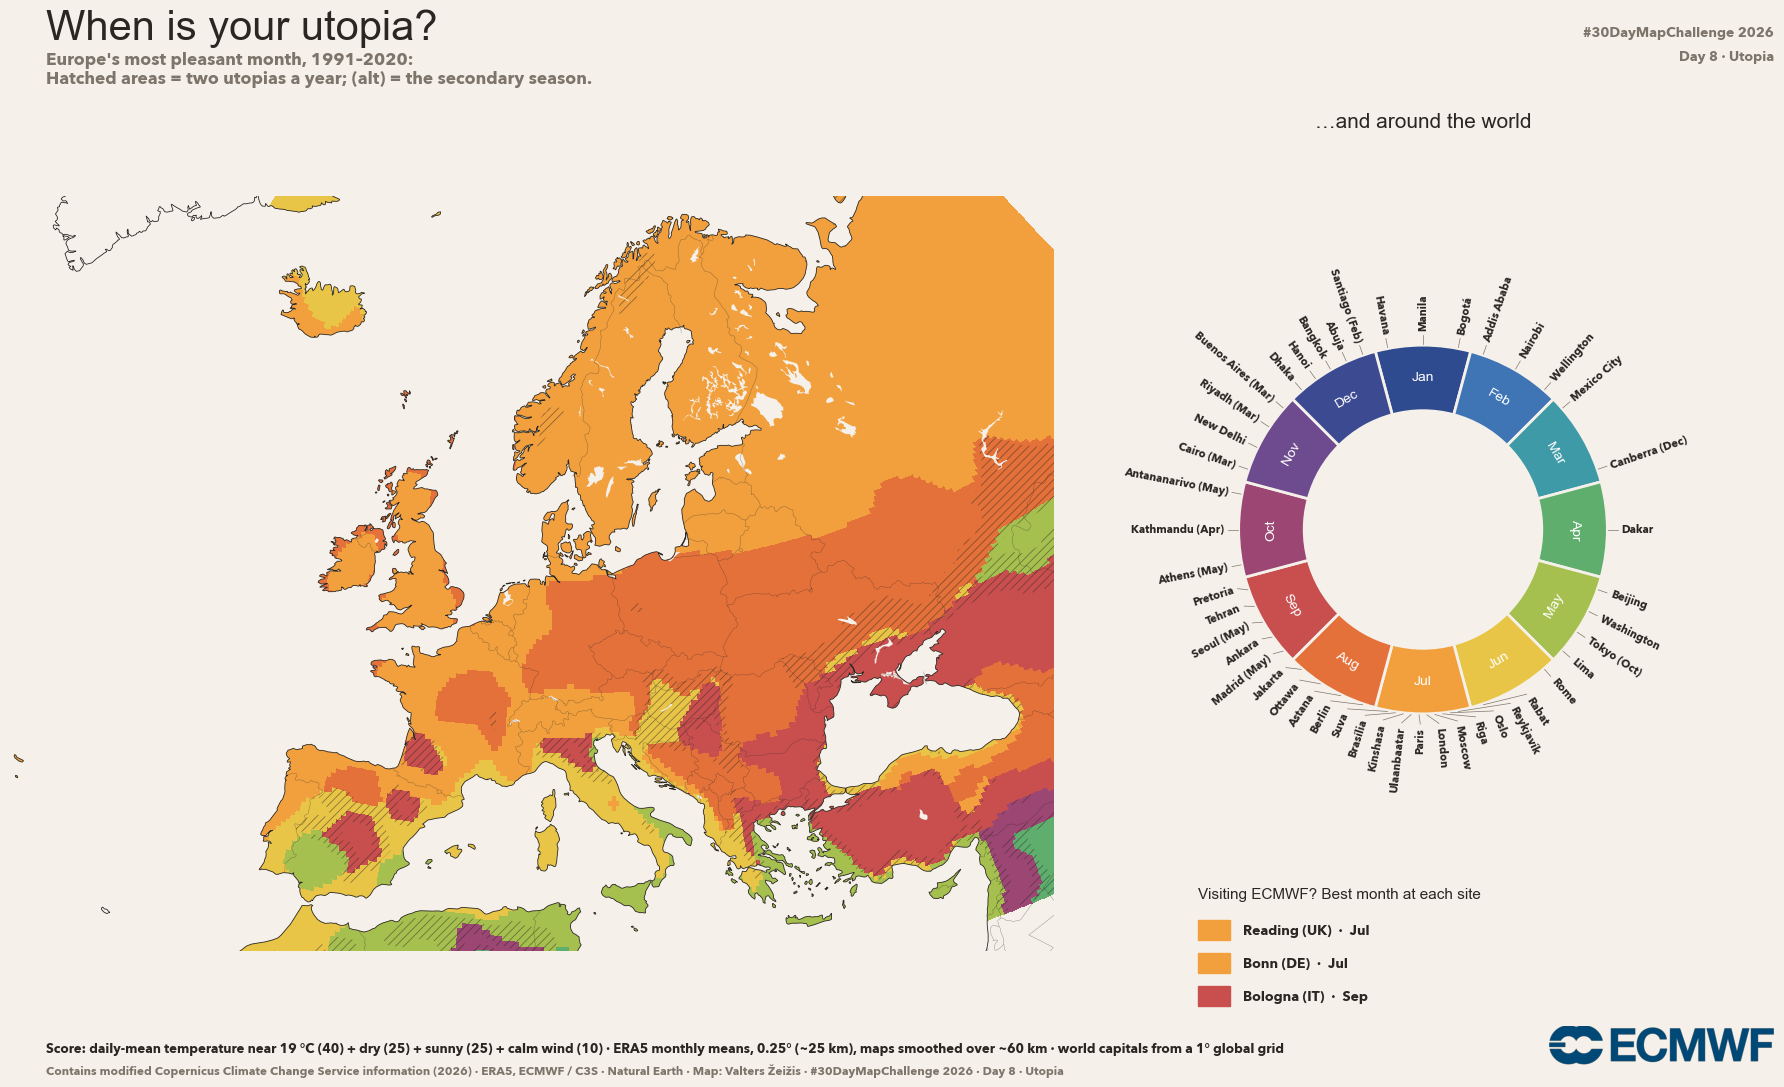

In [6]:
fig = plt.figure(figsize=(18, 11), facecolor=BG)
draw_map(fig, [0.0, 0.07, 0.58, 0.80], maps["europe"],
         ccrs.LambertConformal(central_longitude=10, central_latitude=52, standard_parallels=(40, 62)),
         [-24, 40, 34.5, 70])
draw_clock(fig, [0.62, 0.22, 0.33, 0.58], world_caps)
fig.text(0.785, 0.875, "…and around the world", ha="center", fontsize=15, fontfamily=DB, color=INK)

# visiting ECMWF? the best month at each site, as a small table under the clock
fig.text(0.66, 0.175, "Visiting ECMWF? Best month at each site", fontsize=11, fontfamily=DB, color=INK)
for i, (site, (m, r, _)) in enumerate(sites.items()):
    y = 0.145 - i * 0.03
    fig.patches.append(plt.Rectangle((0.66, y - 0.008), 0.018, 0.018, color=WHEEL[m - 1],
                                     transform=fig.transFigure, figure=fig))
    fig.text(0.685, y, f"{site}  ·  {MONTHS[m - 1]}" + (f" ({MONTHS[r - 1]})" if r else ""),
             fontsize=10, color=INK, va="center")

fig.text(0.02, 0.955, "When is your utopia?", fontsize=30, fontfamily=DB, color=INK)
fig.text(0.02, 0.915, "Europe's most pleasant month, " + SUB, fontsize=12.5, color=MUTED)
credits(fig, " · world capitals from a 1° global grid")
add_logo(fig, white=False); add_tag(fig, 8, "Utopia", MUTED)
fig.savefig("day08_utopia_bestmonth.png", dpi=200, facecolor=BG)
plt.show()

## Bonus: has utopia moved? (Europe)

Same score, two 30-year periods. Swaps between neighbouring summer months are mostly noise, so
only shifts of **two months or more** are shown.

best month moved by 2+ months on 4 % of the map


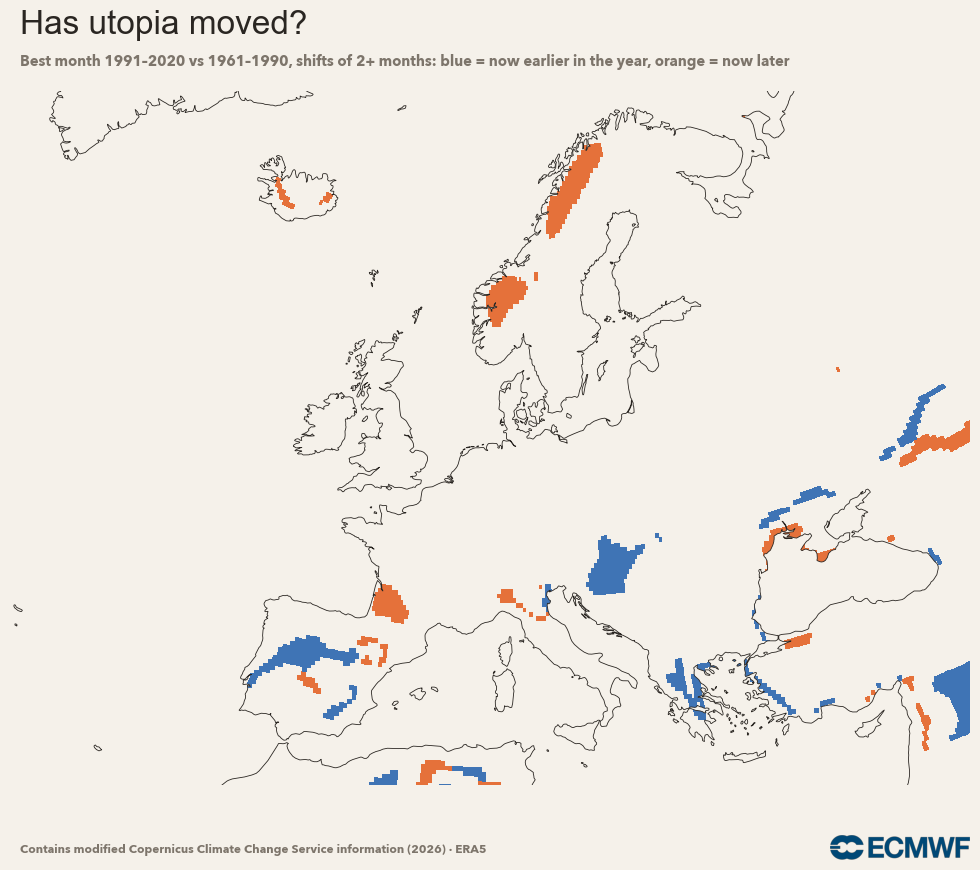

In [7]:
if PERIOD_OLD:
    eu = maps["europe"]
    best_old, _, _ = pick_best(score(climatology(eu["fields"], PERIOD_OLD)), SMOOTH_KM)
    shift = ((eu["best"] - best_old + 6) % 12) - 6        # months, circular: -5..+6
    big = np.abs(shift) >= 2
    print(f"best month moved by 2+ months on {float(big.mean()) * 100:.0f} % of the map")

    proj = ccrs.LambertConformal(central_longitude=10, central_latitude=52, standard_parallels=(40, 62))
    fig2 = plt.figure(figsize=(10, 9), facecolor=BG)
    ax2 = fig2.add_axes([0.02, 0.08, 0.96, 0.82], projection=proj, facecolor=BG)
    ax2.set_extent([-24, 40, 34.5, 70], crs=pc)
    ax2.pcolormesh(shift.longitude, shift.latitude, np.sign(shift).where(big),
                   cmap=mcolors.ListedColormap(["#3f74b5", "#e5713a"]), vmin=-1, vmax=1,
                   transform=pc, shading="nearest", zorder=1)
    ax2.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor=BG, zorder=2)
    ax2.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor=INK, lw=0.6, zorder=3)
    ax2.spines["geo"].set_visible(False)
    fig2.text(0.03, 0.94, "Has utopia moved?", fontsize=24, fontfamily=DB, color=INK)
    fig2.text(0.03, 0.905, f"Best month {PERIOD[0]}–{PERIOD[1]} vs {PERIOD_OLD[0]}–{PERIOD_OLD[1]}, shifts of 2+ months: "
              "blue = now earlier in the year, orange = now later", fontsize=10.5, color=MUTED)
    fig2.text(0.03, 0.03, "Contains modified Copernicus Climate Change Service information (2026) · ERA5",
              fontsize=8.5, color=MUTED)
    add_logo(fig2, white=False, rect=(0.84, 0.01, 0.14, 0.05))
    fig2.savefig("day08_utopia_bestmonth_shift.png", dpi=200, facecolor=BG)
    plt.show()

## Output

`day08_utopia_africa.png` · `day08_utopia_bestmonth.png` (Europe) · `day08_utopia_bestmonth_shift.png`

*Posting idea (Africa):* "When is Africa's utopia? Every place coloured by its most pleasant month,
from 30 years of ERA5. North of the equator it's one season, south of it the opposite, and in East
Africa there are two." (add a few capitals from the printout).